<a href="https://colab.research.google.com/github/prithvee2k4/DSAB13-CaseStudy/blob/main/Customer_Churn_Prediction_Prithvi_Vinayak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

train_data = pd.read_csv("/content/drive/MyDrive/DSAB13/Datasets/Training_data.csv")
test_data = pd.read_csv("/content/drive/MyDrive/DSAB13/Datasets/Testing_data.csv")

print(train_data.shape)
print(test_data.shape)

train_data.head()

(5634, 21)
(1409, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5465 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [ ]:
print("Shape:", train_data.shape)
print("Rows:", train_data.shape[0])
print("Columns:", train_data.shape[1])

Shape: (5634, 21)
Rows: 5634
Columns: 21


In [ ]:
train_data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5634.000000,5634.000000,5240.000000
mean,0.159744,32.606851,65.102052
std,0.366401,24.614976,30.056443
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,36.800000
50%,0.000000,29.000000,70.650000
75%,0.000000,56.000000,90.050000
max,1.000000,72.000000,118.750000


In [ ]:
train_data.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [ ]:
train_data.duplicated().sum()

np.int64(0)

In [ ]:
for col in train_data.columns:
    print(col, ":", train_data[col].nunique())


customerID : 5634
gender : 2
SeniorCitizen : 2
Partner : 2
Dependents : 2
tenure : 73
PhoneService : 2
MultipleLines : 3
InternetService : 3
OnlineSecurity : 3
OnlineBackup : 3
DeviceProtection : 3
TechSupport : 3
StreamingTV : 3
StreamingMovies : 3
Contract : 3
PaperlessBilling : 2
PaymentMethod : 4
MonthlyCharges : 1478
TotalCharges : 5040
Churn : 2


In [ ]:
train_data['Churn'].value_counts()

,count
Churn,
No,4130
Yes,1504


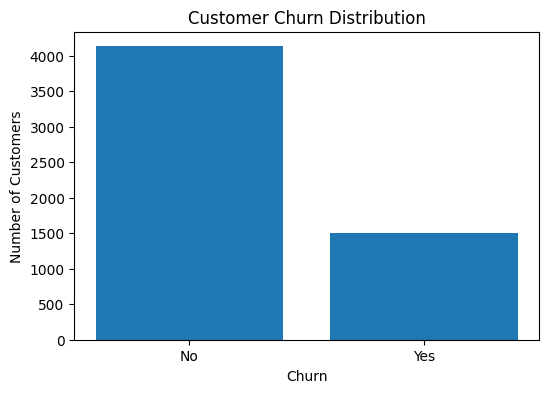

In [ ]:
import matplotlib.pyplot as plt

churn_count = train_data['Churn'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(churn_count.index, churn_count.values)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

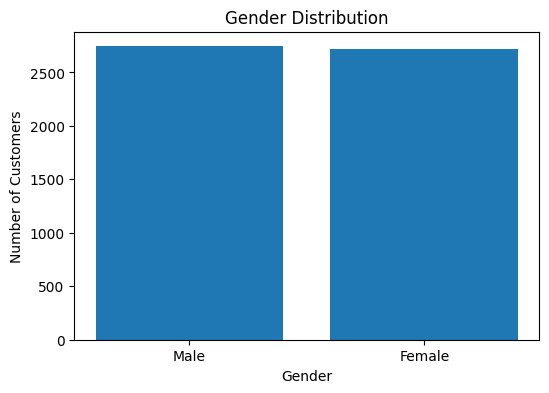

In [ ]:
gender_count = train_data['gender'].value_counts()

plt.figure(figsize=(6,4))
plt.bar(gender_count.index, gender_count.values)

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

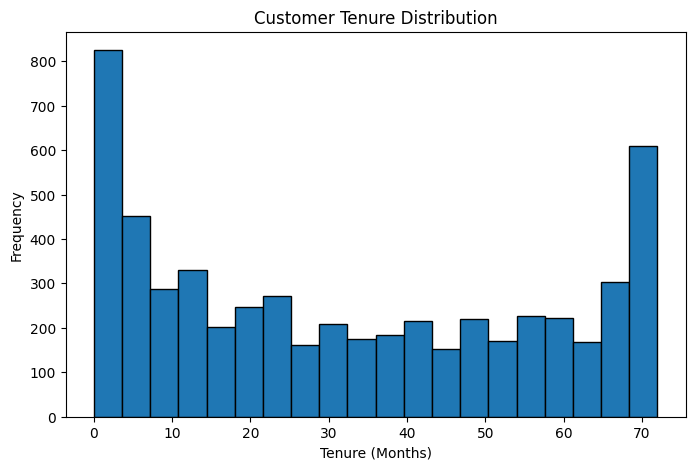

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(train_data['tenure'], bins=20, edgecolor='black')

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Frequency')
plt.show()

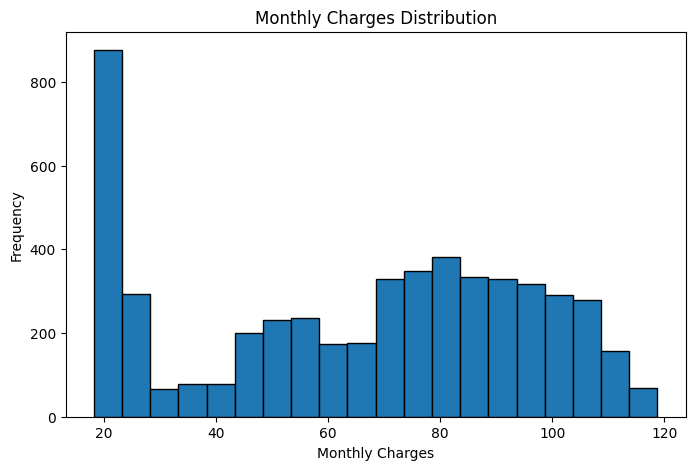

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(train_data['MonthlyCharges'].dropna(),
         bins=20, edgecolor='black')

plt.title('Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency')
plt.show()

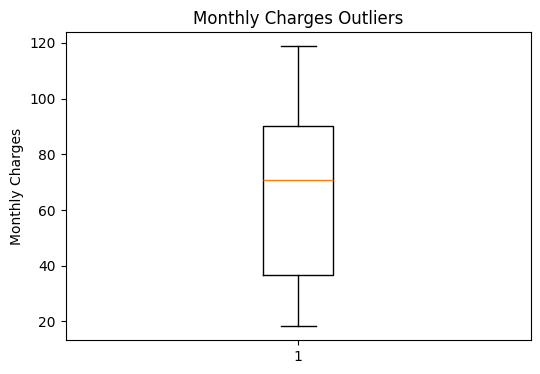

In [ ]:
plt.figure(figsize=(6,4))

plt.boxplot(train_data['MonthlyCharges'].dropna())

plt.title('Monthly Charges Outliers')
plt.ylabel('Monthly Charges')
plt.show()

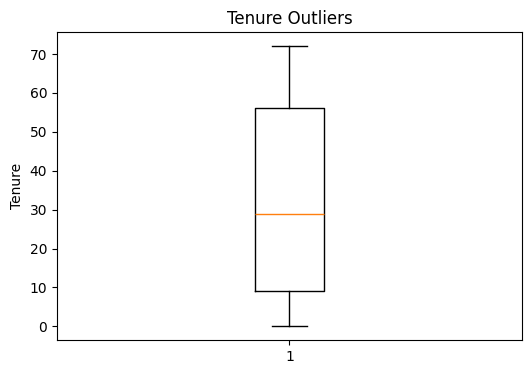

In [ ]:
plt.figure(figsize=(6,4))

plt.boxplot(train_data['tenure'])

plt.title('Tenure Outliers')
plt.ylabel('Tenure')
plt.show()

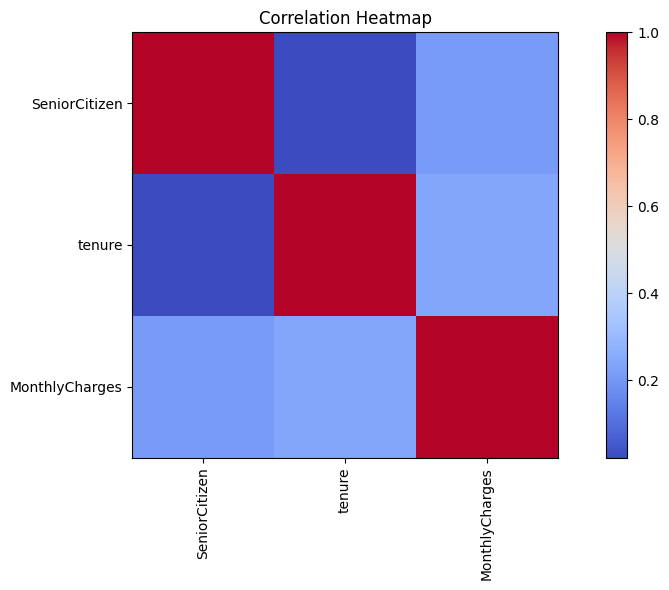

In [ ]:
numeric_data = train_data.select_dtypes(include='number')

correlation = numeric_data.corr()

plt.figure(figsize=(10,6))

plt.imshow(correlation, cmap='coolwarm')
plt.colorbar()

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=90)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
# Convert TotalCharges column from object to numeric datatype
# errors='coerce' converts invalid or empty values into NaN

train_data['TotalCharges'] = pd.to_numeric(
    train_data['TotalCharges'], errors='coerce'
)

test_data['TotalCharges'] = pd.to_numeric(
    test_data['TotalCharges'], errors='coerce'
)

In [ ]:
# Remove customerID because it is only a unique identifier
# It does not provide useful information for predicting customer churn

train_data.drop('customerID', axis=1, inplace=True)

test_data.drop('customerID', axis=1, inplace=True)

In [ ]:
# Check the number of missing values in each column

print("Training Data Missing Values:")
print(train_data.isnull().sum())

print("\nTesting Data Missing Values:")
print(test_data.isnull().sum())

Training Data Missing Values:
gender              169
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity      169
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges      394
TotalCharges        290
Churn                 0
dtype: int64

Testing Data Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        2
Churn               0
dtype: 

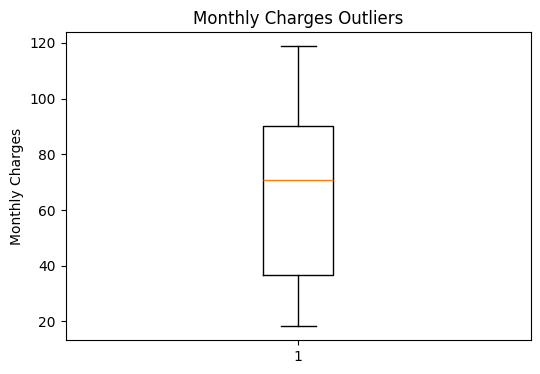

In [ ]:
# Create a boxplot to identify outliers in MonthlyCharges

plt.figure(figsize=(6,4))

plt.boxplot(train_data['MonthlyCharges'].dropna())

plt.title('Monthly Charges Outliers')
plt.ylabel('Monthly Charges')

plt.show()

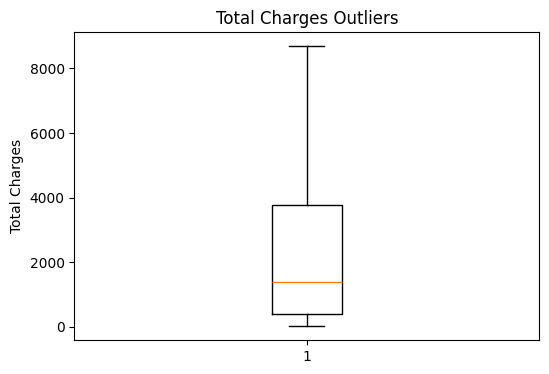

In [ ]:
# Create a boxplot to identify outliers in TotalCharges

plt.figure(figsize=(6,4))

plt.boxplot(train_data['TotalCharges'].dropna())

plt.title('Total Charges Outliers')
plt.ylabel('Total Charges')

plt.show()

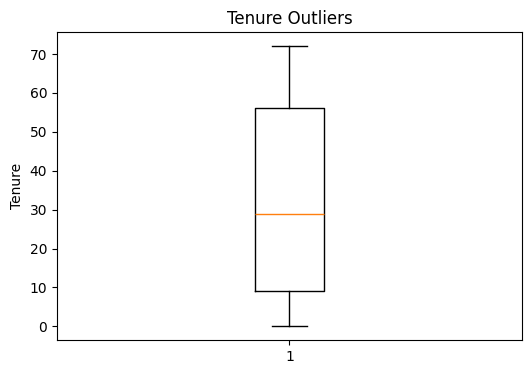

In [ ]:
# Create a boxplot to identify outliers in tenure

plt.figure(figsize=(6,4))

plt.boxplot(train_data['tenure'].dropna())

plt.title('Tenure Outliers')
plt.ylabel('Tenure')

plt.show()

In [ ]:
# Separate independent variables (input features)
# Remove Churn because it is the target variable

X_train = train_data.drop('Churn', axis=1)

# Store Churn as the dependent variable (output)

y_train = train_data['Churn']


# Separate input features from testing data

X_test = test_data.drop('Churn', axis=1)

# Store actual testing results

y_test = test_data['Churn']

In [ ]:
# Select columns containing numerical values

numeric_cols = X_train.select_dtypes(include='number').columns

# Select columns containing categorical values

categorical_cols = X_train.select_dtypes(include='object').columns

# Display numerical columns

print("Numerical Columns:")
print(list(numeric_cols))

# Display categorical columns

print("\nCategorical Columns:")
print(list(categorical_cols))

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Import required preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# Create numerical preprocessing pipeline

numeric_transformer = Pipeline([

    # Replace missing numerical values with the median
    ('imputer', SimpleImputer(strategy='median')),

    # Scale numerical values into a common range
    ('scaler', StandardScaler())

])


# Create categorical preprocessing pipeline

categorical_transformer = Pipeline([

    # Replace missing categorical values with the most frequent value
    ('imputer', SimpleImputer(strategy='most_frequent')),

    # Convert categorical values into numerical format
    ('encoder', OneHotEncoder(handle_unknown='ignore'))

])


# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer([

    # Apply numerical transformations
    ('num', numeric_transformer, numeric_cols),

    # Apply categorical transformations
    ('cat', categorical_transformer, categorical_cols)

])

In [ ]:
train_data['CLV'] = train_data['tenure'] * train_data['MonthlyCharges']

test_data['CLV'] = test_data['tenure'] * test_data['MonthlyCharges']

train_data[['tenure', 'MonthlyCharges', 'CLV']].head()

,tenure,MonthlyCharges,CLV
0,35,20.75,726.25
1,28,35.75,1001.00
2,56,98.60,5521.60
3,39,20.45,797.55
4,43,51.25,2203.75


In [ ]:
# Combine tenure and contract type into one new feature

train_data['Tenure_Contract'] = (
    train_data['tenure'].astype(str) + '_' + train_data['Contract']
)

test_data['Tenure_Contract'] = (
    test_data['tenure'].astype(str) + '_' + test_data['Contract']
)

# Display the new feature
train_data[['tenure', 'Contract', 'Tenure_Contract']].head()

,tenure,Contract,Tenure_Contract
0,35,One year,35_One year
1,28,Month-to-month,28_Month-to-month
2,56,Month-to-month,56_Month-to-month
3,39,Two year,39_Two year
4,43,One year,43_One year


In [ ]:
train_data[['tenure', 'Contract', 'CLV', 'Tenure_Contract']].head()

,tenure,Contract,CLV,Tenure_Contract
0,35,One year,726.25,35_One year
1,28,Month-to-month,1001.00,28_Month-to-month
2,56,Month-to-month,5521.60,56_Month-to-month
3,39,Two year,797.55,39_Two year
4,43,One year,2203.75,43_One year


In [ ]:
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (5634, 22)
Testing data: (1409, 22)


In [ ]:
# X contains the input features
# y contains the target column that we want to predict

X_train = train_data.drop('Churn', axis=1)
y_train = train_data['Churn']

X_test = test_data.drop('Churn', axis=1)
y_test = test_data['Churn']

# Display the shapes
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5634, 21)
y_train: (5634,)
X_test: (1409, 21)
y_test: (1409,)


In [ ]:
# Select numerical columns
numeric_cols = X_train.select_dtypes(include='number').columns

# Select categorical columns
categorical_cols = X_train.select_dtypes(include='object').columns

print("Numerical columns:")
print(list(numeric_cols))

print("\nCategorical columns:")
print(list(categorical_cols))

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_Contract']


In [ ]:
# Import the required preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing:
# Fill missing values using the median
# Scale numerical values using StandardScaler

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing:
# Fill missing values using the most frequent value
# Convert categorical values into numerical values using OneHotEncoder

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

In [ ]:
# Import three classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# Create a dictionary containing the three models

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

In [ ]:
# Store the model evaluation results
results = []

# Train and test each model
for name, model in models.items():

    # Create a pipeline with preprocessing and the model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train the model using training data
    pipeline.fit(X_train, y_train)

    # Predict churn using testing data
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label='Yes')
    recall = recall_score(y_test, y_pred, pos_label='Yes')
    f1 = f1_score(y_test, y_pred, pos_label='Yes')

    # Store the results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    # Print the model results
    print("\nModel:", name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    # Display the classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))


Model: Logistic Regression
Accuracy: 0.8126330731014905
Precision: 0.6634304207119741
Recall: 0.5616438356164384
F1 Score: 0.6083086053412463

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.90      0.88      1044
         Yes       0.66      0.56      0.61       365

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.81      0.81      0.81      1409


Model: Decision Tree
Accuracy: 0.7437899219304471
Precision: 0.5052910052910053
Recall: 0.5232876712328767
F1 Score: 0.5141318977119784

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.82      0.83      1044
         Yes       0.51      0.52      0.51       365

    accuracy                           0.74      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.75      0.74      0.75      1409


Model: Random For

In [ ]:
# Convert the results into a DataFrame
results_df = pd.DataFrame(results)

# Display the comparison table
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.812633,0.663430,0.561644,0.608309
1,Decision Tree,0.743790,0.505291,0.523288,0.514132
2,Random Forest,0.790632,0.625000,0.479452,0.542636


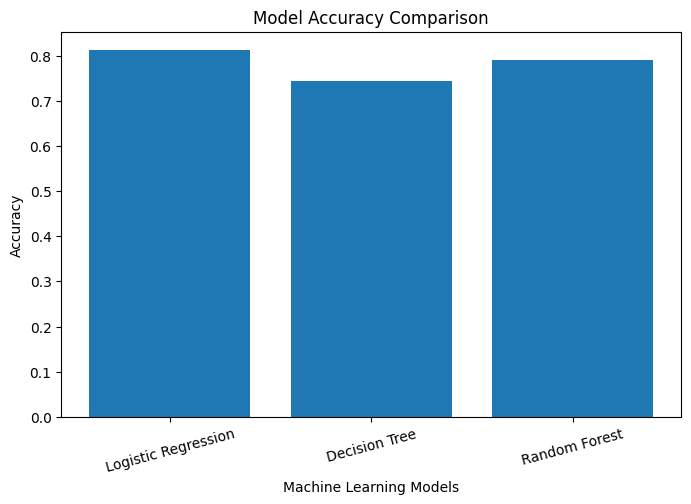

In [ ]:
# Plot the accuracy of the three models

plt.figure(figsize=(8, 5))

plt.bar(results_df['Model'], results_df['Accuracy'])

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')

plt.xticks(rotation=15)
plt.show()

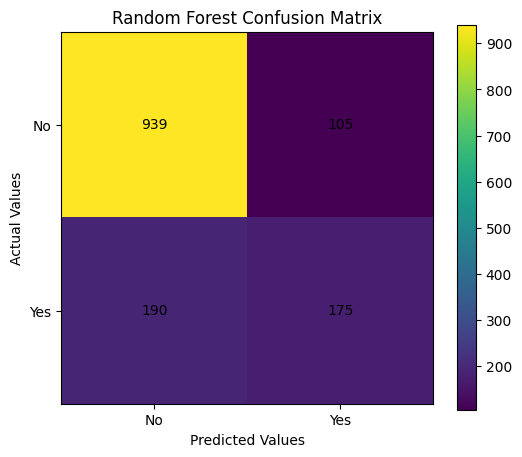

In [ ]:
# Select the Random Forest model for confusion matrix analysis

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

# Train the Random Forest model
rf_pipeline.fit(X_train, y_train)

# Predict the testing data
rf_predictions = rf_pipeline.predict(X_test)

# Generate the confusion matrix
cm = confusion_matrix(y_test, rf_predictions, labels=['No', 'Yes'])

# Display the confusion matrix
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])

# Display the values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

In [ ]:
# Get the trained Random Forest model
rf_model = rf_pipeline.named_steps['model']

# Get the transformed feature names after preprocessing
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get the importance values
importance = rf_model.feature_importances_

# Create a DataFrame containing feature names and importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort features from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display the top 15 important features
feature_importance.head(15)

,Feature,Importance
3,num__TotalCharges,0.100071
4,num__CLV,0.097076
2,num__MonthlyCharges,0.085320
1,num__tenure,0.073429
37,cat__Contract_Month-to-month,0.038863
44,cat__PaymentMethod_Electronic check,0.025218
19,cat__OnlineSecurity_No,0.022818
17,cat__InternetService_Fiber optic,0.021872
28,cat__TechSupport_No,0.019402
77,cat__Tenure_Contract_1_Month-to-month,0.016129


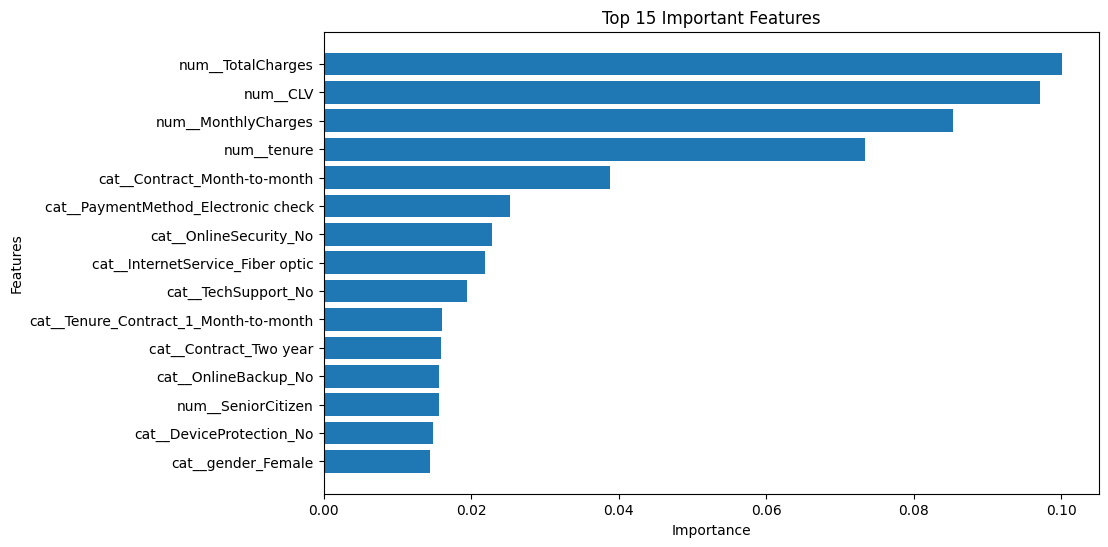

In [ ]:
# Select the top 15 important features
top_features = feature_importance.head(15)

# Plot the feature importance
plt.figure(figsize=(10, 6))

plt.barh(top_features['Feature'], top_features['Importance'])

plt.title('Top 15 Important Features')
plt.xlabel('Importance')
plt.ylabel('Features')

# Display the most important feature at the top
plt.gca().invert_yaxis()

plt.show()

In [ ]:
# Import GridSearchCV and make_scorer

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

In [ ]:
# Create a pipeline containing preprocessing and Random Forest

rf_tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

In [ ]:
# Define different Random Forest settings to test

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

In [ ]:
# Use F1 score with Yes as the positive class
f1_scorer = make_scorer(f1_score, pos_label='Yes')

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

# Train and find the best hyperparameters
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Parameters:")
print(grid_search.best_params_)

# Display the best cross-validation score
print("\nBest Cross-validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best Cross-validation F1 Score:
0.5698543568559447


In [ ]:
# Get the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Predict using the testing data
tuned_predictions = best_model.predict(X_test)

# Calculate evaluation metrics
print("Tuned Model Accuracy:",
      accuracy_score(y_test, tuned_predictions))

print("Tuned Model Precision:",
      precision_score(y_test, tuned_predictions, pos_label='Yes'))

print("Tuned Model Recall:",
      recall_score(y_test, tuned_predictions, pos_label='Yes'))

print("Tuned Model F1 Score:",
      f1_score(y_test, tuned_predictions, pos_label='Yes'))

Tuned Model Accuracy: 0.8034066713981547
Tuned Model Precision: 0.658273381294964
Tuned Model Recall: 0.5013698630136987
Tuned Model F1 Score: 0.5692068429237948


In [ ]:
# Calculate the F1 score before tuning
before_tuning = f1_score(y_test, rf_predictions, pos_label='Yes')

# Calculate the F1 score after tuning
after_tuning = f1_score(y_test, tuned_predictions, pos_label='Yes')

# Display the comparison
print("Before Tuning F1 Score:", before_tuning)
print("After Tuning F1 Score:", after_tuning)

Before Tuning F1 Score: 0.5426356589147286
After Tuning F1 Score: 0.5692068429237948


**Conclusion:**

The Customer Churn Prediction project aims to identify customers who are likely to leave a telecom company.
- EDA was performed to understand the dataset and identify patterns.
- Missing values and categorical features were handled during preprocessing.
- Feature engineering was performed by creating CLV and Tenure_Contract.
- Three machine learning models were trained and compared.
- Model performance was evaluated using accuracy, precision, recall and F1 score.
- Random Forest was selected for hyperparameter tuning using GridSearchCV.
- Important features were identified to understand the factors influencing customer churn.


**Business Recommendations:**
- Identify customers who have a high probability of leaving.
- Provide special offers to customers with short tenure.
- Improve customer support services.
- Encourage customers to choose long-term contracts.
- Investigate payment methods and service-related issues associated with churn.